# 02 · Churn model: reproduce, challenge, calibrate to a real base

**Summary.** The production model is reproduced exactly: hold-out AUC 0.6722 (train 0.7403), logistic 0.6011, top-decile churn 53.9%
(lift 1.87) and 45.9% of churners in the riskiest 30%. A tuned LightGBM on 48 inputs (the ETL's 23, plus 13 behavioural
fields and 12 engineered ratios, still no demographics) reaches **AUC 0.682 (95% CI 0.674-0.692), +0.010 over the
champion (paired CI +0.006 to +0.014)**, and lifts top-decile churn from 53.9% to 56.0%. Tree models beat a properly built
logistic pipeline by 5-6 AUC points (0.621); the published 0.601 was further handicapped by zero-filled blanks. Handset
age, tenure and usage change drive the score, and SHAP and permutation importance agree (rank correlation 0.93). The
retention-call fields add almost nothing (removing them costs 0.002 AUC), so the model is not just re-finding customers
who already asked to leave. The score is calibrated on the sample's 28.8% scale. After a prior correction to a real
base, the riskiest decile churns at about 5.6% a month, not 54%. An AUC near 0.67 is in line with what is usually reported
for Cell2Cell and close to what these fields can support (the last 40% of training rows add 0.007): good enough to rank,
not to be sure. **Recommendation:** promote the challenger after a month of shadow scoring, and take the economics
(notebook 03) from prior-corrected probabilities.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

In [2]:
import copy, time
import lightgbm as lgb
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
threadpool_limits(4)                         # HistGradientBoosting would otherwise use every core; other jobs share this machine
T0 = time.perf_counter()

## 1. Reproduce the production model

The ETL splits the 51,047 subscribers 70/30 at random, stratified on churn (seed 42), trains a
`HistGradientBoostingClassifier` on 23 fields and compares it with a scaled logistic regression. The data is a
single snapshot with no dates, so an out-of-time test is not possible; the random hold-out is the honest best and the
model card says so. Reproduce every published model metric before changing anything.

In [3]:
d = F.load()
y = d["Churned"].values
X = F.etl_matrix(d)
tr, te = F.split(d)
y_tr, y_te = y[tr], y[te]
champion = HistGradientBoostingClassifier(**F.GBM_PARAMS).fit(X.iloc[tr], y_tr)
p_champ = champion.predict_proba(X.iloc[te])[:, 1]
etl_logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5)).fit(X.iloc[tr].fillna(0), y_tr)
p_etl_logit = etl_logit.predict_proba(X.iloc[te].fillna(0))[:, 1]
dec = F.deciles(np.round(p_champ, 4))                              # the ETL ranks the rounded score it publishes
pub = pd.read_csv(ROOT / "data" / "model_metrics.csv").set_index("Metric")["Value"]
mine = {"churn_auc_test": roc_auc_score(y_te, p_champ), "churn_auc_train": roc_auc_score(y_tr, champion.predict_proba(X.iloc[tr])[:, 1]),
        "churn_auc_logit": roc_auc_score(y_te, p_etl_logit), "churn_top_decile_rate": y_te[dec == 1].mean(),
        "churn_top_decile_lift": y_te[dec == 1].mean() / y_te.mean(), "churn_top_30_capture": y_te[dec <= 3].sum() / y_te.sum()}
parity = pd.DataFrame({"published": pub[list(mine)], "reproduced": pd.Series(mine)})
parity["abs_diff"] = (parity["reproduced"] - parity["published"]).abs()
assert (parity.drop("churn_top_decile_lift")["abs_diff"] <= 0.005).all() and parity.loc["churn_top_decile_lift", "abs_diff"] <= 0.01, parity
parity

,published,reproduced,abs_diff
churn_auc_test,0.6722,0.6722,0.0000
churn_auc_train,0.7403,0.7403,0.0000
churn_auc_logit,0.6011,0.6011,0.0000
churn_top_decile_rate,0.5385,0.5385,0.0000
churn_top_decile_lift,1.8700,1.8684,0.0016
churn_top_30_capture,0.4588,0.4588,0.0000


All published model metrics are reproduced exactly: hold-out AUC 0.6722 (train 0.7403), logistic 0.6011, top-decile
churn 53.9% (lift 1.87) and 45.9% of churners in the riskiest 30%. The train-test gap of 0.07 AUC says the champion
fits some noise; section 3 checks whether a more regularised model generalises better.

## 2. Preprocessing pipeline and engineered features

The published logistic regression fills blanks with 0 and scales raw, heavy-tailed fields, which is a handicap rather
than a fair linear baseline. The pipeline below does it properly, with every step fitted inside the training fold:
median imputation with missing flags, a signed log to tame the tails, scaling, then an L2-penalised logistic
regression. The challenger features add the behavioural fields the ETL left out and the engineered ratios from
notebook 01 (still no demographics).

In [4]:
XF = F.full_matrix(d)
print(f"Champion features: {X.shape[1]}; challenger features: {XF.shape[1]} (+{len(F.EXTRA_NUM)} behavioural, +{len(F.ENGINEERED)} engineered)")


def logit_pipeline(C=0.1):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), FunctionTransformer(F.signed_log1p), StandardScaler(),
                         LogisticRegression(C=C, max_iter=3000))


cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
c_grid = {C: cross_val_score(logit_pipeline(C), XF.iloc[tr], y_tr, cv=cv3, scoring="roc_auc").mean()
          for C in (0.003, 0.03, 0.3, 3)}
BEST_C = max(c_grid, key=c_grid.get)
print("3-fold CV AUC by C:", {k: round(v, 4) for k, v in c_grid.items()}, "-> C =", BEST_C)
eng_auc = pd.Series({f: max(a, 1 - a) for f in F.ENGINEERED for a in [roc_auc_score(y_tr, XF.iloc[tr][f].fillna(XF.iloc[tr][f].median()))]},
                    name="single_feature_auc_train").sort_values(ascending=False)
eng_auc.to_frame()

Champion features: 23; challenger features: 48 (+13 behavioural, +12 engineered)


3-fold CV AUC by C: {0.003: np.float64(0.6279), 0.03: np.float64(0.6287), 0.3: np.float64(0.6285), 3: np.float64(0.6285)} -> C = 0.03


,single_feature_auc_train
handset_age_years,0.5754
revenue_per_minute,0.5494
minutes_change_rel,0.5451
recurring_share,0.5308
care_per_100_calls,0.5256
overage_share,0.5185
handset_price_missing,0.5179
unanswered_share,0.5089
drop_rate,0.5057
usage_missing,0.5046


Regularisation barely matters for the logistic pipeline: 0.628-0.629 across a 1,000x range of C. Among the engineered
ratios, handset age in years (0.575, the same signal as the raw days), revenue per minute (0.549) and minutes change
against the customer's own usage (0.545) are the strongest. The others are weak alone and can only help in combination.

## 3. Candidates on identical folds

Three-fold stratified CV on the training 70% only (the hold-out stays untouched), with the same folds for every model:

* **Rule**: handset age alone (the strongest single field).
* **ETL logistic**: as published (blanks to 0, scaling).
* **Logistic pipeline**: imputation + flags + signed log + scaling + L2, on the challenger features.
* **Champion**: the production gradient-boosting model on its 23 features.
* **Challenger**: LightGBM on the challenger features, tuned with Optuna (20 trials on the same folds).

In [5]:
t_tune = time.perf_counter()
best_params, study = select.tune_lgbm(XF.iloc[tr].reset_index(drop=True), y_tr, cv3, n_trials=20, timeout=600, seed=SEED)   # trial count binds: reproducible
print(f"Best 3-fold CV AUC {study.best_value:.4f} after {len(study.trials)} trials ({time.perf_counter() - t_tune:.0f}s):",
      {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items() if k not in ("verbose", "n_jobs", "random_state", "subsample_freq")})

Best 3-fold CV AUC 0.6877 after 20 trials (94s): {'n_estimators': 400, 'learning_rate': 0.0214, 'num_leaves': 15, 'min_child_samples': 138, 'subsample': 0.7139, 'colsample_bytree': 0.6517, 'reg_lambda': 1.819}


In [6]:
rule = make_pipeline(ColumnTransformer([("h", SimpleImputer(strategy="median"), ["CurrentEquipmentDays"])]), LogisticRegression())
etl_logit_model = make_pipeline(FunctionTransformer(lambda Z: Z.fillna(0)), StandardScaler(), LogisticRegression(max_iter=5000, C=0.5))
CH, CL, LG, LE = "Champion (production GBM)", "Challenger (tuned LightGBM)", f"Logistic pipeline (C={BEST_C})", "ETL logistic (as published)"
CANDS = {"Rule: handset age": (rule, X), LE: (etl_logit_model, X), LG: (logit_pipeline(BEST_C), XF),
         CH: (HistGradientBoostingClassifier(**F.GBM_PARAMS), X), CL: (lgb.LGBMClassifier(**best_params), XF)}
cv_rows = []
for name, (m, M) in CANDS.items():
    t = select.cv_compare({name: m}, M.iloc[tr].reset_index(drop=True), y_tr, cv3, scoring=("roc_auc", "average_precision"))
    cv_rows.append(t)
cvt = pd.concat(cv_rows)
cvt

,fit_seconds,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
model,,,,,
Rule: handset age,0.0600,0.5754,0.0048,0.3383,0.0077
ETL logistic (as published),0.2500,0.6087,0.0044,0.3701,0.0045
Logistic pipeline (C=0.03),0.5900,0.6287,0.0033,0.4005,0.0056
Champion (production GBM),1.8200,0.6748,0.0039,0.4535,0.0053
Challenger (tuned LightGBM),4.1100,0.6877,0.0043,0.4764,0.0047


On the training folds the challenger leads (0.688), ahead of the champion (0.675), the logistic pipeline (0.629), the ETL
logistic (0.609) and the handset-age rule (0.575). The challenger's CV score is optimistic, because it was tuned on these
folds. The untouched hold-out decides.

## 4. The untouched hold-out: champion vs challenger

In [7]:
preds, fitted = {}, {}
for name, (m, M) in CANDS.items():
    fitted[name] = m.fit(M.iloc[tr], y_tr)
    preds[name] = fitted[name].predict_proba(M.iloc[te])[:, 1]
assert abs(roc_auc_score(y_te, preds[CH]) - pub["churn_auc_test"]) <= 0.005 and abs(roc_auc_score(y_te, preds[LE]) - pub["churn_auc_logit"]) <= 0.005
mt = evaluate.metrics_table(y_te, preds, n_boot=500, seed=SEED)
mt

,AUC,AUC 95% CI,PR AUC,PR AUC 95% CI,KS,Brier,Log loss
model,,,,,,,
Rule: handset age,0.5724,0.563 - 0.582,0.3326,0.324 - 0.342,0.1648,0.2033,0.5958
ETL logistic (as published),0.6011,0.592 - 0.611,0.3673,0.357 - 0.379,0.1526,0.1999,0.5875
Logistic pipeline (C=0.03),0.6208,0.611 - 0.630,0.3931,0.382 - 0.406,0.1737,0.1974,0.5817
Champion (production GBM),0.6722,0.664 - 0.681,0.4515,0.440 - 0.464,0.2456,0.1890,0.5607
Challenger (tuned LightGBM),0.6823,0.674 - 0.692,0.4683,0.456 - 0.481,0.2629,0.1867,0.5553


In [8]:
tests = pd.DataFrame({f"{a} vs {b}": evaluate.paired_auc_test(y_te, preds[a], preds[b], n=1000, seed=SEED)
                      for a, b in ((CL, CH), (CH, LG), (CL, LG), (LG, LE), (CH, "Rule: handset age"))}).T
tests

,delta_auc,ci_low,ci_high,p_value_one_sided
Challenger (tuned LightGBM) vs Champion (production GBM),0.0101,0.0062,0.0140,0.0000
Champion (production GBM) vs Logistic pipeline (C=0.03),0.0514,0.0430,0.0601,0.0000
Challenger (tuned LightGBM) vs Logistic pipeline (C=0.03),0.0615,0.0530,0.0699,0.0000
Logistic pipeline (C=0.03) vs ETL logistic (as published),0.0198,0.0127,0.0266,0.0000
Champion (production GBM) vs Rule: handset age,0.0999,0.0885,0.1100,0.0000


In [9]:
gains = {k: evaluate.gains_table(y_te, p) for k, p in preds.items()}
lift = pd.DataFrame({k: {"top_decile_churn": g.loc[1, "rate"], "top_decile_lift": g.loc[1, "lift"], "top_30_capture": g.loc[3, "cum_capture"]}
                     for k, g in gains.items()}).T
lift

,top_decile_churn,top_decile_lift,top_30_capture
Rule: handset age,0.3473,1.2049,0.3446
ETL logistic (as published),0.4223,1.4653,0.3858
Logistic pipeline (C=0.03),0.4641,1.6103,0.4096
Champion (production GBM),0.5385,1.8684,0.4588
Challenger (tuned LightGBM),0.5601,1.9432,0.4683


**Decision.**

* **The challenger wins on evidence.** It gains +0.010 AUC (CI +0.006 to +0.014) and is better at the top of the list,
  where offers go (top-decile churn 56.0% vs 53.9%, lift 1.94 vs 1.87). It is also slightly better calibrated (Brier
  0.1867 vs 0.1890) and ranks the same way on the training folds (0.688 vs 0.675). It needs 25 more inputs, all from the
  billing and network feeds the champion already reads, and none of them demographic.
* **The gain is modest.** In money terms (notebook 03), two points of top-decile churn are worth less than getting the
  offer price right. Promote through the normal gate: shadow-score one month, check segment AUC and calibration, then
  switch. The published numbers (0.6722) remain the production record until then.
* **Linear models are not competitive here** (0.60-0.62). Churn in this base follows non-linear shapes, such as the
  tenure effect that peaks at 12-17 months and then falls, and interactions between usage level and usage change. Trees
  capture these; an additive model on log scales does not. The published logistic also loses 0.02 AUC to zero-filled
  blanks and unscaled tails.

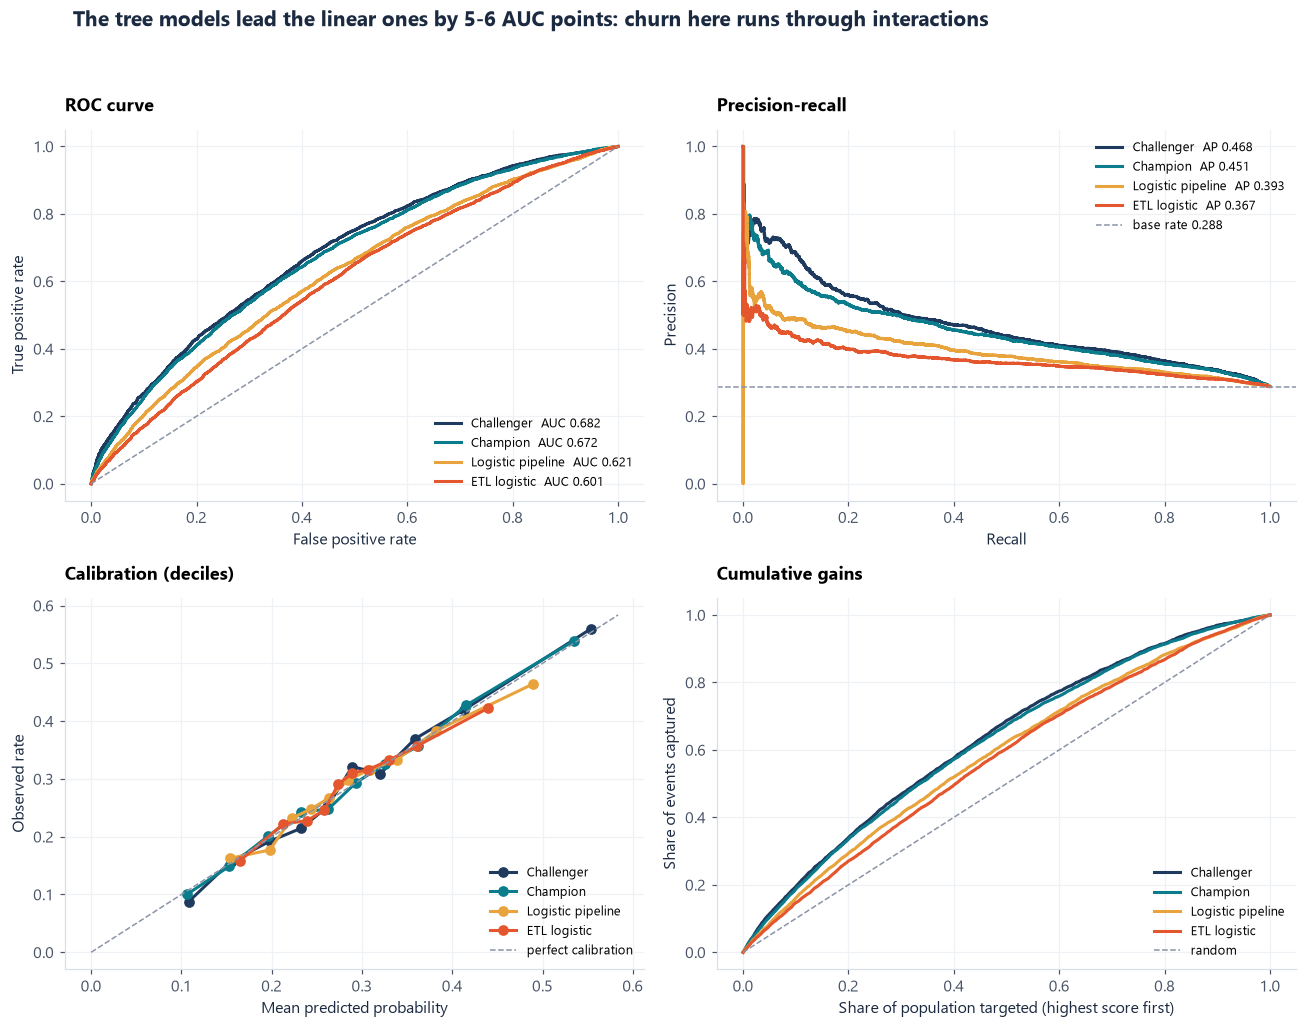

In [10]:
fig = evaluate.plot_binary_panel(y_te, {"Challenger": preds[CL], "Champion": preds[CH], "Logistic pipeline": preds[LG], "ETL logistic": preds[LE]},
                                 suptitle="The tree models lead the linear ones by 5-6 AUC points: churn here runs through interactions")
savefig(fig, "02-model-comparison", FIG); plt.show()

## 5. Calibration and the prior correction

On the sample's own scale, the champion should be roughly calibrated, because it was trained on the same 28.8% mix.
A real base churns at about 2% a month (an assumption; see notebook 01). The Bayes prior correction rescales the odds
by (true odds / sample odds) = 0.050. It can be checked on this hold-out: if the sample over-represents churners and
not particular kinds of churner, reweighting churners by 0.069 and stayers by 1.377 recreates the real base, and the
corrected probabilities should match the reweighted churn rate decile by decile.

In [11]:
w_te = F.population_weights(y_te)
p_pop = F.prior_correct(p_champ)
cal = evaluate.calibration_table(y_te, p_champ, 10)
dec10 = pd.qcut(pd.Series(p_champ).rank(method="first"), 10, labels=False).values
cal["predicted_population"] = pd.Series(p_pop).groupby(dec10).mean().values
cal["observed_population"] = pd.Series(y_te * w_te).groupby(dec10).sum().values / pd.Series(w_te).groupby(dec10).sum().values
cal.index = 10 - cal.index
cal = cal.sort_index()
cal.index.name = "risk decile (1 = highest)"
sens = pd.DataFrame({f"assumed {r:.0%}": {"mean_predicted": F.prior_correct(p_champ, true_rate=r).mean(),
                                         "top_decile_predicted": F.prior_correct(p_champ, true_rate=r)[dec == 1].mean()} for r in (0.01, 0.02, 0.03)}).T
display(cal); sens

,predicted,observed,rows,predicted_population,observed_population
risk decile (1 = highest),,,,,
1,0.5344,0.5385,1532,0.0572,0.0555
2,0.4151,0.4272,1531,0.0346,0.0362
3,0.3622,0.3564,1532,0.0279,0.0272
4,0.3254,0.3259,1531,0.0238,0.0238
5,0.2932,0.2933,1531,0.0205,0.0205
6,0.2629,0.2480,1532,0.0177,0.0164
7,0.2322,0.2423,1531,0.0150,0.0159
8,0.1961,0.2010,1532,0.0122,0.0125
9,0.1532,0.1489,1531,0.0090,0.0087


,mean_predicted,top_decile_predicted
assumed 1%,0.0113,0.0293
assumed 2%,0.0224,0.0572
assumed 3%,0.0334,0.0840


On the sample's scale, predictions and outcomes agree decile by decile (mean 28.8% vs 28.8%). After the prior correction,
the riskiest decile is predicted at 5.7% and the reweighted hold-out churns at 5.6%; the safest decile sits at 0.6%. This
is a consistency check, not an independent validation. It confirms the arithmetic and that the sample-scale calibration
carries over, but the 2% base rate itself is an assumption that only billing data can confirm. At a 1% or 3% base, the
top decile's probability would be 2.9% or 8.4%.

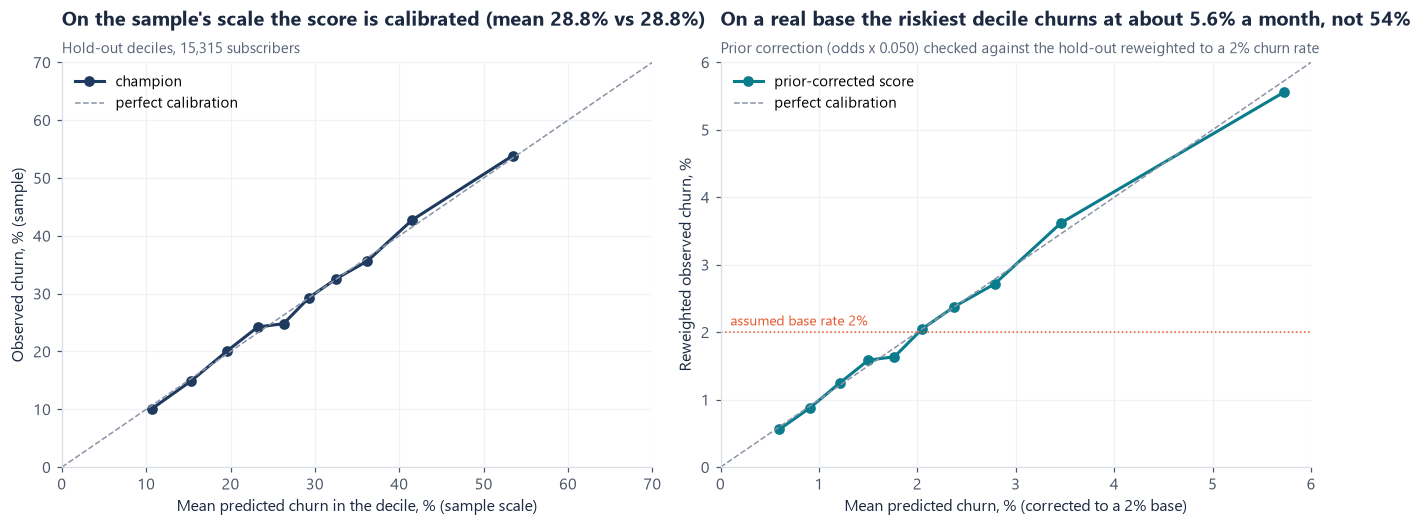

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.9))
a1.plot(cal["predicted"] * 100, cal["observed"] * 100, marker="o", color=PALETTE["navy"], label="champion")
a1.plot([0, 70], [0, 70], ls="--", color=PALETTE["grey"], lw=1, label="perfect calibration")
a1.set(xlabel="Mean predicted churn in the decile, % (sample scale)", ylabel="Observed churn, % (sample)", xlim=(0, 70), ylim=(0, 70))
a1.legend(loc="upper left")
headline(a1, f"On the sample's scale the score is calibrated (mean {p_champ.mean():.1%} vs {y_te.mean():.1%})", "Hold-out deciles, 15,315 subscribers")
a2.plot(cal["predicted_population"] * 100, cal["observed_population"] * 100, marker="o", color=PALETTE["teal"], label="prior-corrected score")
a2.plot([0, 6], [0, 6], ls="--", color=PALETTE["grey"], lw=1, label="perfect calibration")
a2.axhline(F.ASSUMED_MONTHLY_CHURN * 100, color=PALETTE["coral"], ls=":", lw=1)
a2.text(0.1, F.ASSUMED_MONTHLY_CHURN * 100 + 0.1, f"assumed base rate {F.ASSUMED_MONTHLY_CHURN:.0%}", color=PALETTE["coral"], fontsize=9)
a2.set(xlabel="Mean predicted churn, % (corrected to a 2% base)", ylabel="Reweighted observed churn, %", xlim=(0, 6), ylim=(0, 6))
a2.legend(loc="upper left")
headline(a2, f"On a real base the riskiest decile churns at about {cal.loc[1, 'observed_population']:.1%} a month, not {cal.loc[1, 'observed']:.0%}",
         "Prior correction (odds x 0.050) checked against the hold-out reweighted to a 2% churn rate")
fig.tight_layout()
savefig(fig, "02-calibration", FIG); plt.show()

## 6. Segment performance

Does the model rank equally well across tenure, credit class, revenue band and handset age?

In [13]:
seg = F.bands(d.iloc[te]).reset_index(drop=True).assign(churn=y_te, p=p_champ)
segperf = pd.concat({s: evaluate.segment_performance(seg, s, "churn", "p", min_n=300) for s in ("TenureBand", "CreditClass", "ARPUBand", "HandsetAgeBand")},
                    names=["segment", "level"])
segperf

rows  base_rate  mean_pred  calibration_ratio    auc
segment        level                                                                
TenureBand     12-17 months     3963     0.3343     0.3309             0.9897 0.6318
               18-23 months     2921     0.2893     0.2989             1.0334 0.6328
               24-35 months     3153     0.2946     0.2954             1.0027 0.6542
               36+ months       1003     0.2642     0.2815             1.0656 0.6882
               Under 12 months  4275     0.2456     0.2372             0.9656 0.7179
CreditClass    Good             2533     0.3143     0.3038             0.9668 0.6699
               High             5712     0.2994     0.2990             0.9987 0.6703
               Highest          2567     0.3023     0.3086             1.0207 0.6547
               Low              1954     0.2226     0.2323             1.0434 0.6753
               Lowest            649     0.3082     0.2716             0.8814 0.6610
               Medium           1554     0.2625     0.2673             1.0182 0.6688
               VeryLow           346     0.2572     0.2812             1.0931 0.6799
ARPUBand       $30-45           4848     0.2828     0.2810             0.9938 0.6858
               $45-60           3093     0.2965     0.2771             0.9346 0.6703
               $60-80           2207     0.2719     0.2816             1.0357 0.6717
               $80+             2915     0.2738     0.2806             1.0251 0.6536
               Under $30        2200     0.3191     0.3307             1.0365 0.6577
HandsetAgeBand 12-18 months     3201     0.3261     0.3269             1.0024 0.6176
               18-24 months     1931     0.3200     0.3249             1.0151 0.6334
               24+ months       1580     0.3481     0.3599             1.0339 0.6018
               6-12 months      5704     0.2716     0.2617             0.9635 0.7098
               Under 6 months   2898     0.2253     0.2335             1.0362 0.6631

AUC ranges from 0.60 (handsets 24+ months old) to 0.72 (tenure under 12 months). In the oldest-handset group almost
everyone is at risk, so ranking inside it is hard. Calibration holds within 0.93-1.09 in every segment except the Lowest
credit class (0.88: 30.8% observed vs 27.2% predicted), a small group (649 subscribers) to monitor.

## 7. What drives the score

SHAP on a 2,000-subscriber sample of the hold-out (log-odds), cross-checked with permutation importance. Then two
leakage-sensitivity refits: without the retention-contact fields, and without the "blank usage history" signal.

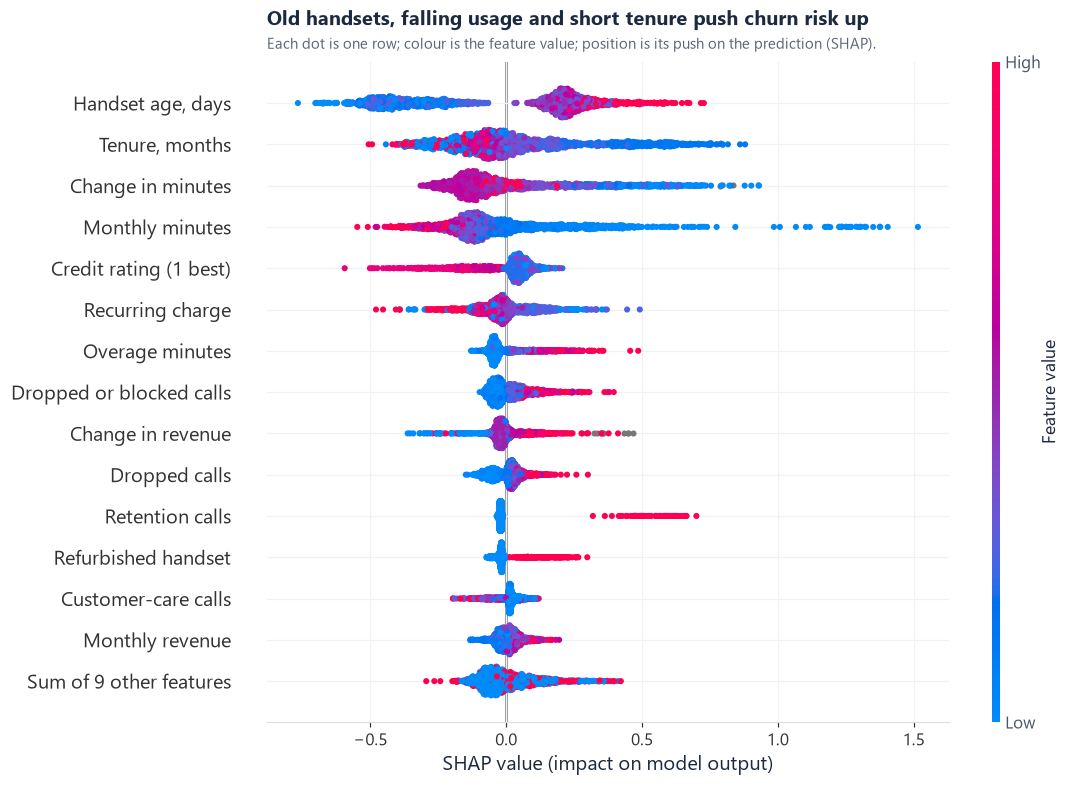

In [14]:
e = explain.shap_explanation(champion, X.iloc[te], sample=2000, seed=SEED)
e_lab = copy.copy(e)
e_lab.feature_names = [F.LABEL[f] for f in e.feature_names]
fig = explain.plot_shap_beeswarm(e_lab, max_display=15, title="Old handsets, falling usage and short tenure push churn risk up")
savefig(fig, "02-shap", FIG); plt.show()

In [15]:
shap_imp = explain.shap_importance(e)
perm = explain.permutation_table(champion, X.iloc[te], y_te, n_repeats=3, seed=SEED, labels=F.LABEL)
imp = shap_imp.join(perm[["drop_mean", "drop_std"]])
imp["shap_rank"], imp["perm_rank"] = imp["mean_abs_shap"].rank(ascending=False).astype(int), imp["drop_mean"].rank(ascending=False).astype(int)
pub_drivers = pd.read_csv(ROOT / "data" / "churn_drivers.csv")
print("Spearman rank correlation, SHAP vs permutation:", round(imp["mean_abs_shap"].corr(imp["drop_mean"], method="spearman"), 3))
print("Published top-3 drivers (ETL permutation):", ", ".join(pub_drivers["Driver"].head(3)))
imp.round(4).head(12)

Spearman rank correlation, SHAP vs permutation: 0.929
Published top-3 drivers (ETL permutation): Handset age, Tenure, Monthly minutes


,mean_abs_shap,share,drop_mean,drop_std,shap_rank,perm_rank
feature,,,,,,
CurrentEquipmentDays,0.3058,0.2070,0.0556,0.0019,1,1
MonthsInService,0.1808,0.1224,0.0420,0.0012,2,2
PercChangeMinutes,0.1743,0.1180,0.0322,0.0012,3,4
MonthlyMinutes,0.1739,0.1177,0.0383,0.0020,4,3
credit,0.0827,0.0560,0.0083,0.0007,5,6
TotalRecurringCharge,0.0736,0.0499,0.0151,0.0009,6,5
OverageMinutes,0.0605,0.0410,0.0043,0.0010,7,9
DroppedBlockedCalls,0.0509,0.0345,0.0034,0.0007,8,11
PercChangeRevenues,0.0445,0.0301,0.0050,0.0006,9,7


Handset age, tenure, minutes change and minutes lead in both SHAP and permutation importance (rank correlation 0.93),
which matches the published driver chart (handset age, tenure, monthly minutes). The beeswarm gives the directions: old
handsets and falling or low usage raise risk; long tenure, a high recurring charge and a *worse* credit rating lower it,
as notebook 01 found. Retention calls touch few subscribers but push their scores up sharply.

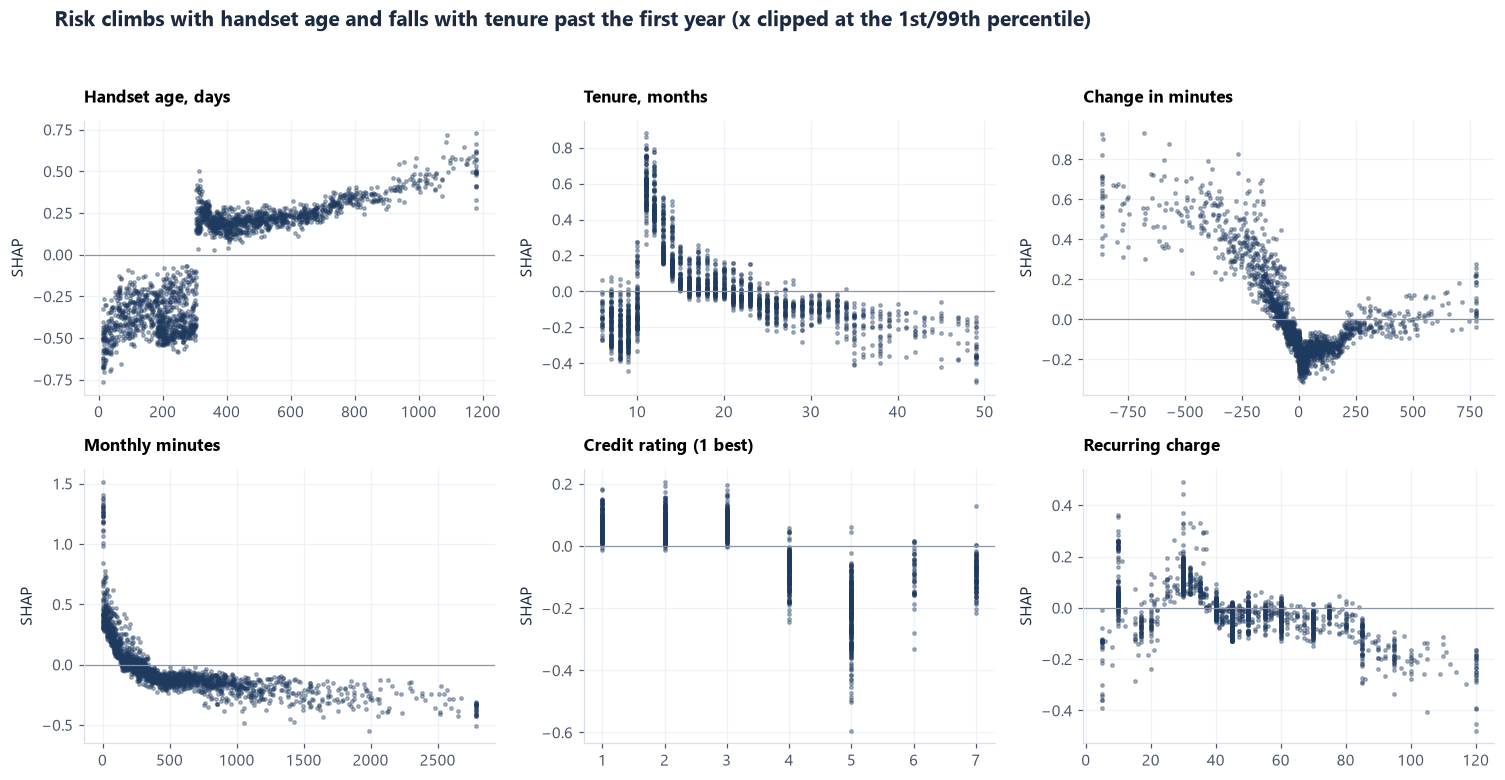

In [16]:
top = list(shap_imp.index[:6])
e_clip = copy.copy(e_lab)
e_clip.data = np.column_stack([np.clip(e.data[:, j], np.nanpercentile(e.data[:, j], 1), np.nanpercentile(e.data[:, j], 99)) for j in range(e.data.shape[1])])
fig = explain.plot_shap_dependence(e_clip, [F.LABEL[f] for f in top], ncols=3,
                                   title="Risk climbs with handset age and falls with tenure past the first year (x clipped at the 1st/99th percentile)")
plt.show()

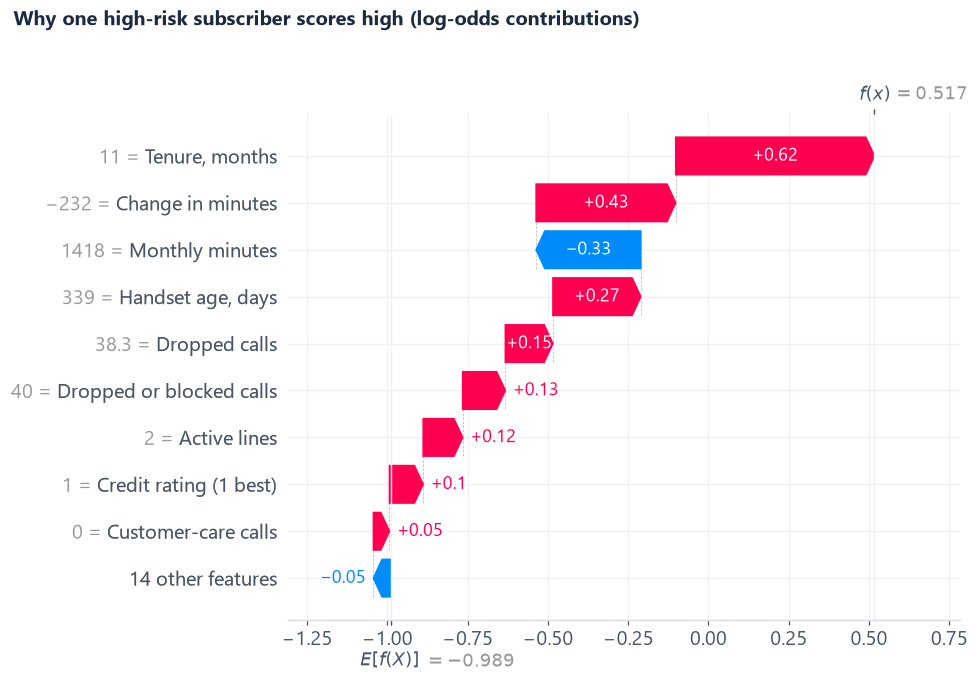

In [17]:
pe = e.values.sum(1) + e.base_values
fig = explain.plot_shap_waterfall(e_lab, int(np.argsort(pe)[-30]), title="Why one high-risk subscriber scores high (log-odds contributions)")
plt.show()

In [18]:
drop_ret = [c for c in X.columns if c not in ("retention_call", "RetentionCalls", "RetentionOffersAccepted")]
m_noret = HistGradientBoostingClassifier(**F.GBM_PARAMS).fit(X.iloc[tr][drop_ret], y_tr)
p_noret = m_noret.predict_proba(X.iloc[te][drop_ret])[:, 1]
fill = X.copy()
miss = d["PercChangeMinutes"].isna().values
fill.loc[miss, ["PercChangeMinutes", "PercChangeRevenues"]] = X.iloc[tr][["PercChangeMinutes", "PercChangeRevenues"]].median().values
m_nomiss = HistGradientBoostingClassifier(**F.GBM_PARAMS).fit(fill.iloc[tr], y_tr)
p_nomiss = m_nomiss.predict_proba(fill.iloc[te])[:, 1]
leak = pd.DataFrame({"Without retention-contact fields": evaluate.paired_auc_test(y_te, p_noret, p_champ, n=500, seed=SEED),
                     "Without the blank-usage signal": evaluate.paired_auc_test(y_te, p_nomiss, p_champ, n=500, seed=SEED)}).T
retc = d["MadeCallToRetentionTeam"].iloc[te].eq("Yes").values
print(f"Retention callers in the champion's top decile: {retc[dec == 1].mean():.1%} (base {retc.mean():.1%}); "
      f"AUC among subscribers who never called: {roc_auc_score(y_te[~retc], p_champ[~retc]):.4f}")
leak

Retention callers in the champion's top decile: 14.8% (base 3.2%); AUC among subscribers who never called: 0.6695


,delta_auc,ci_low,ci_high,p_value_one_sided
Without retention-contact fields,-0.0021,-0.0045,0.0003,0.9580
Without the blank-usage signal,-0.0007,-0.0024,0.0013,0.7620


Removing all three retention-contact fields costs 0.002 AUC (CI -0.004 to +0.000), and among subscribers who never called
the retention team the champion still scores 0.670. Retention callers are 4.6 times over-represented in the top decile
(14.8% vs 3.2%), so they should go to the retention team's own process rather than count as model wins. The blank-usage
signal is worth 0.001 AUC. Neither leakage risk carries the model.

## 8. Error analysis

False alarms (riskiest 30%, stayed) vs correctly flagged churners, and missed churners (safest half, churned) vs
correctly cleared stayers. Medians of the main drivers:

In [19]:
rk = pd.Series(p_champ).rank(pct=True, ascending=False).values
grp = np.select([(rk <= 0.3) & (y_te == 1), (rk <= 0.3) & (y_te == 0), (rk > 0.5) & (y_te == 1), (rk > 0.5) & (y_te == 0)],
                ["Flagged, churned", "False alarm", "Missed churner", "Cleared, stayed"], "Middle 20%")
prof = d.iloc[te].assign(group=grp, minutes_change_rel=F.engineer(d.iloc[te])["minutes_change_rel"].values)
errors = prof.groupby("group").agg(subscribers=("Churned", "size"), handset_age_days=("CurrentEquipmentDays", "median"),
                                   tenure_months=("MonthsInService", "median"), monthly_revenue=("MonthlyRevenue", "median"),
                                   minutes=("MonthlyMinutes", "median"), minutes_change_rel=("minutes_change_rel", "median"),
                                   care_calls=("CustomerCareCalls", "median"), retention_caller=("MadeCallToRetentionTeam", lambda s: (s == "Yes").mean()))
errors.loc[["Flagged, churned", "False alarm", "Missed churner", "Cleared, stayed"]]

,subscribers,handset_age_days,tenure_months,monthly_revenue,minutes,minutes_change_rel,care_calls,retention_caller
group,,,,,,,,
"Flagged, churned",2025,382.0000,15.0000,45.5150,277.0000,-0.1987,0.0000,0.0943
False alarm,2569,393.0000,16.0000,46.4400,313.5000,-0.1895,0.0000,0.0740
Missed churner,1441,265.0000,16.0000,51.0900,434.5000,0.0247,0.3000,0.0139
"Cleared, stayed",6217,237.0000,15.0000,50.4700,440.0000,0.0217,0.3000,0.0071


**False alarms look like the churners next to them.** Both groups have a handset about 390 days old, 15-16 months of
tenure, minutes down about 19% against their own average, and bills around $46 a month. **Missed churners look like the
subscribers correctly cleared**: newer handsets (265 vs 237 days), stable usage and slightly higher bills. In both cases
nothing in these fields separates the two groups, so this is the error floor of this data. What is missing is information
from the moment of decision: contract end dates, competitor offers and the latest bill.

## 9. Is the model data-limited?

Learning curve of the champion: 3-fold CV AUC on growing shares of the training data.

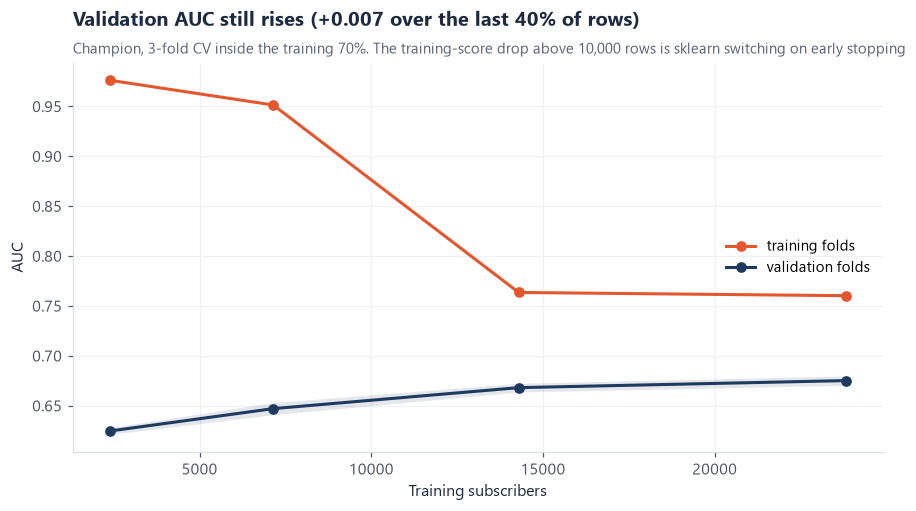

,train_rows,train_score,valid_score,valid_std
0,2382,0.9761,0.6245,0.0034
1,7146,0.9513,0.6470,0.0061
2,14292,0.7634,0.6680,0.0044
3,23821,0.7601,0.6750,0.0047


In [20]:
lc = select.learning_curve_table(HistGradientBoostingClassifier(**F.GBM_PARAMS), X.iloc[tr], y_tr,
                                 cv3, sizes=(0.1, 0.3, 0.6, 1.0))
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.plot(lc["train_rows"], lc["train_score"], marker="o", color=PALETTE["coral"], label="training folds")
ax.plot(lc["train_rows"], lc["valid_score"], marker="o", color=PALETTE["navy"], label="validation folds")
ax.fill_between(lc["train_rows"], lc["valid_score"] - lc["valid_std"], lc["valid_score"] + lc["valid_std"], color=PALETTE["navy"], alpha=0.12, lw=0)
ax.set_xlabel("Training subscribers"); ax.set_ylabel("AUC"); ax.legend(loc="center right")
gain = lc["valid_score"].iloc[-1] - lc["valid_score"].iloc[-2]
headline(ax, f"Validation AUC {'still rises' if gain > 0.002 else 'has flattened'} (+{gain:.3f} over the last 40% of rows)",
         "Champion, 3-fold CV inside the training 70%. The training-score drop above 10,000 rows is sklearn switching on early stopping")
savefig(fig, "02-learning-curve", FIG); plt.show()
lc

Validation AUC climbs from 0.625 on 2,400 rows to 0.675 on 23,800, but the last 40% of rows add only 0.007. The model is
close to what these fields can support, and more data of the same kind would help only a little. The fall in training AUC
above 10,000 rows is sklearn's automatic early stopping switching on, not a change in the data.

## 10. What an AUC of about 0.67 means for targeting

* **0.67 is the data, not the method.** No single field separates churners (best single-feature AUC 0.57, notebook 01).
  Four model families with different preprocessing land between 0.60 and 0.68, and the learning curve says more rows of the
  same fields would add little. This is in line with what is usually reported for this dataset.
* **What it means for targeting.** The top decile churns at 1.9x the base rate. On a real base that is about 5.6% a month
  instead of 2%, so about nineteen of every twenty subscribers offered a deal would have stayed anyway. Offers must be
  cheap, or sized to each subscriber's expected value, and the business case rests on the save rate (notebook 03).
* **What it does not mean.** The model is useful. The riskiest 30% hold 46% of churners, and ranked by revenue at risk the
  top 30% hold 58% of churned revenue. A ranking this good, combined with a measured save rate and a cheap offer, is a
  business case. Without those two, it is not.

## 11. Monitoring plan

| What | How | Threshold | Action |
|---|---|---|---|
| Feature drift | PSI of each input vs the training data, every monthly scoring run | > 0.10 watch, > 0.25 investigate | Check the source feed (billing, network, care), then refit |
| Score drift | PSI of the score distribution month on month | > 0.25 | Hold the campaign until explained |
| Base rate | Real monthly churn from billing | Outside 1.5%-2.5% | Update the prior correction |
| Discrimination | AUC and top-decile lift on last month's matured list | AUC < 0.65 or lift < 1.6 | Refit; review features |
| Causal value | Churn in offered vs random hold-out (keep 10-20% of the list un-offered) | Save-rate CI excludes the planning value | Re-plan the budget (notebook 03) |

Retrain quarterly, or when a threshold trips. Every refit is a challenger that must beat the live model on a paired
test before it replaces it.

## Limitations

* **No time dimension.** The data is one snapshot, so the split is random, not out-of-time. Next month's list is the
  real test, and a drifting base (handset cycles, price changes) will lower performance.
* **Over-sampled churners.** The 2% real churn rate is an assumption. The prior correction also assumes churners were
  sampled at random among churners (no particular kind over-represented).
* **Field timing is not fully documented**, for retention calls in particular. The sensitivity refit shows the model does
  not depend on them.
* **Fairness.** Age, marital status, occupation and household fields are excluded. Credit rating is used, and it is a
  financial attribute that can proxy for protected characteristics. Ranking quality is similar across credit classes
  (AUC 0.65-0.68), but churn is under-predicted for the Lowest class (calibration ratio 0.88), a group to monitor.
* **Old data.** The carrier data is from the early 2000s, so the drivers (handset age above all) may weigh differently
  today.

## What I would do next

1. Shadow-score the challenger for a month, then promote it if segment AUC and calibration hold.
2. Run the randomised save-rate test designed in notebook 03; nothing else moves the business case as much.
3. Collect dated monthly snapshots so validation can be out of time and features can describe change over time.
4. Once the test has run, model uplift (who is persuadable) rather than risk (who will leave).

In [21]:
ci = lambda name: [float(x) for x in mt.loc[name, "AUC 95% CI"].split(" - ")]
report.update_metrics(METRICS, "02_churn_model", {
    "parity": {k: {"published": float(v["published"]), "reproduced": float(v["reproduced"])} for k, v in parity.iterrows()},
    "test_auc": {name: {"auc": float(mt.loc[name, "AUC"]), "ci": ci(name)} for name in mt.index},
    "cv_auc_mean": {name: float(v) for name, v in cvt["roc_auc_mean"].items()},
    "paired_tests": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in tests.iterrows()},
    "lift": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in lift.iterrows()},
    "prior_correction": {"assumed_monthly_churn": F.ASSUMED_MONTHLY_CHURN, "top_decile_population_rate": float(cal.loc[1, "observed_population"]),
                         "top_decile_predicted_population": float(cal.loc[1, "predicted_population"])},
    "leakage_sensitivity": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in leak.iterrows()},
    "learning_curve_last_gain": float(gain),
})
print(f"metrics written; notebook runtime {time.perf_counter() - T0:.0f}s")

metrics written; notebook runtime 337s
